##### Master Degree in Computer Science and Data Science for Economics and Health

# Word2Vec: representing words by their context

### Prof. Alfio Ferrara

## Introduction

At the end of the previous notebook we had two kinds of vectors for the same ingredients. The vectors of our network said which ingredients *behave in the same way with respect to the cuisine*: `cilantro` with `jack` and `tortilla`, `tofu` with `soy` and `mirin`. The vectors of spaCy said which words *are used in similar ways in the language*: `cilantro` with `coriander`, `tofu` with `chicken` and `pork`. And the second ones were built **without any label**. The question that we left open is how it is possible to build the representation of a word from the text alone.

The idea is old and simple, and it is often attributed to the linguist J. R. Firth: *you shall know a word by the company it keeps*. Two words that occur in the same contexts, such as `coffee` and `tea` in *she drinks ...*, are probably used in the same way, whatever the cuisine. We can turn this idea into a task that needs no labels: **given a word, predict the words that occur around it**. The text provides both the questions and the answers, and this is why it is called a *self-supervised* task.

As in the previous notebook, the network is a means: we are not interested in the prediction, but in the vectors that the network builds in order to make it. What changes is the task, and with the task changes what the vectors capture: no longer the cuisine, but the way in which a word is used. The model that does it is **Word2Vec** (Mikolov et al., 2013).

## A toy example

We start again from an invented example, small enough to see everything. The corpus is made of 400 sentences of three words, generated by a simple rule. There are three people (`anna`, `marco`, `luca`), four drinks, four foods and five verbs. The verb `drinks` is only used with drinks, `eats` and `cooks` are only used with foods, while `buys` and `likes` can be used with both.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

people = ["anna", "marco", "luca"]
drinks = ["coffee", "tea", "milk", "juice"]
foods = ["bread", "pasta", "rice", "cake"]

rng = np.random.default_rng(0)
sentences = []
for _ in range(400):
    person, kind = rng.choice(people), rng.random()
    if kind < 0.3:
        sentences.append([person, "drinks", rng.choice(drinks)])
    elif kind < 0.6:
        sentences.append([person, "eats", rng.choice(foods)])
    elif kind < 0.8:
        sentences.append([person, "cooks", rng.choice(foods)])
    else:
        sentences.append([person, rng.choice(["buys", "likes"]), rng.choice(drinks + foods)])

vocabulary = sorted({word for sentence in sentences for word in sentence})
index = {word: i for i, word in enumerate(vocabulary)}

print(f"{len(sentences)} sentences, {len(vocabulary)} words")
for sentence in sentences[:8]:
    print(" ".join(sentence))

400 sentences, 16 words
luca drinks milk
anna drinks coffee
anna likes bread
marco cooks rice
marco buys rice
luca buys bread
anna cooks cake
anna buys bread


### From the text to the training pairs

The training examples are **pairs** made of a *center word* and a *context word*. For each word of the text we take as context the words that are at a distance of at most $m$ from it, where $m$ is the **window**. Here the window is 2, and since a sentence has three words, every word is in the window of the other two. The sentence `anna drinks tea` produces six pairs: `(anna, drinks)`, `(anna, tea)`, `(drinks, anna)`, `(drinks, tea)`, `(tea, anna)`, `(tea, drinks)`.

In [2]:
window = 2

def make_pairs(sentences, window):
    pairs = []
    for sentence in sentences:
        ids = [index[word] for word in sentence]
        for i, center in enumerate(ids):
            for j in range(max(0, i - window), min(len(ids), i + window + 1)):
                if j != i:
                    pairs.append((center, ids[j]))
    return np.array(pairs)

pairs = make_pairs(sentences, window)
print(f"{len(pairs)} pairs")

pd.DataFrame([(vocabulary[c], vocabulary[o]) for c, o in make_pairs([sentences[0]], window)],
             columns=["center", "context"])

2400 pairs


,center,context
0,luca,drinks
1,luca,milk
2,drinks,luca
3,drinks,milk
4,milk,luca
5,milk,drinks


### The model

The model is the network of the previous notebook, with another input and another output.

- The input is the **one-hot** vector of the center word $c$.
- The hidden layer has $d$ neurons and **no activation function**. It is a matrix $V$ with a row for each word of the vocabulary and, since the input is a one-hot vector, the hidden vector of the word $c$ is simply its row, $v_c$. This is the **vector of the word** that we are looking for. Here $d = 2$, so that we can draw it.
- The output layer has a neuron for each word of the vocabulary, with a softmax. It has its own matrix $U$, with a row $u_w$ for each word, and it gives a probability distribution over the words that can be found near $c$:

$$P(o \mid c) = \frac{\exp(u_o \cdot v_c)}{\sum_{w} \exp(u_w \cdot v_c)}$$

Each word has therefore **two vectors**: $v_w$ when it is the center, $u_w$ when it is the context. After the training we keep the vectors $v$.

The loss is the one of the classification, the average of $-\log P(o \mid c)$ over the pairs, and the gradient has the same simple form that we already know for the softmax with the cross-entropy: if $p$ is the output distribution and $y$ the one-hot vector of the context word, the error is $p - y$, and

$$\frac{\partial L}{\partial u_w} = (p_w - y_w)\, v_c \qquad \frac{\partial L}{\partial v_c} = \sum_w (p_w - y_w)\, u_w$$

Notice that **there are no labels**: the target of each pair is a word, and it comes from the text.

In [3]:
def softmax(Z):
    E = np.exp(Z - Z.max(axis=1, keepdims=True))
    return E / E.sum(axis=1, keepdims=True)

def train_skipgram(pairs, vocabulary_size, d, epochs=1000, learning_rate=1.0, seed=0):
    rng = np.random.default_rng(seed)
    V = rng.normal(scale=0.1, size=(vocabulary_size, d))     # vectors of the words as centers
    U = rng.normal(scale=0.1, size=(vocabulary_size, d))     # vectors of the words as contexts
    center, context = pairs[:, 0], pairs[:, 1]
    n = len(pairs)
    history = []
    for epoch in range(epochs):
        h = V[center]                                        # hidden vectors, one for each pair
        P = softmax(h @ U.T)                                 # distribution over the context words
        history.append(-np.log(P[np.arange(n), context]).mean())
        error = P.copy()
        error[np.arange(n), context] -= 1                    # p - y
        error /= n
        grad_U = error.T @ h
        grad_V = np.zeros_like(V)
        np.add.at(grad_V, center, error @ U)                 # sum of the gradients of the pairs with the same center
        V -= learning_rate * grad_V
        U -= learning_rate * grad_U
    return V, U, np.array(history)

runs = [train_skipgram(pairs, len(vocabulary), d=2, seed=seed) for seed in range(5)]
pd.DataFrame({"final loss": [history[-1] for _, _, history in runs]}).rename_axis("seed").style.format("{:.3f}")

,final loss
seed,
0,2.193
1,2.283
2,2.237
3,2.191
4,2.192


In [4]:
# The lowest loss that a model that looks only at the center word can reach: the conditional entropy of the context
pair_counts = Counter(map(tuple, pairs))
center_counts = Counter(pairs[:, 0])
floor = -sum(n / len(pairs) * np.log(n / center_counts[c]) for (c, o), n in pair_counts.items())

best = min(range(len(runs)), key=lambda s: runs[s][2][-1])
V_toy, U_toy, history = runs[best]
print(f"Seed {best}: final loss {history[-1]:.3f}; lowest possible loss for these data {floor:.3f}; loss of a random model {np.log(len(vocabulary)):.3f}")

Seed 3: final loss 2.191; lowest possible loss for these data 2.061; loss of a random model 2.773


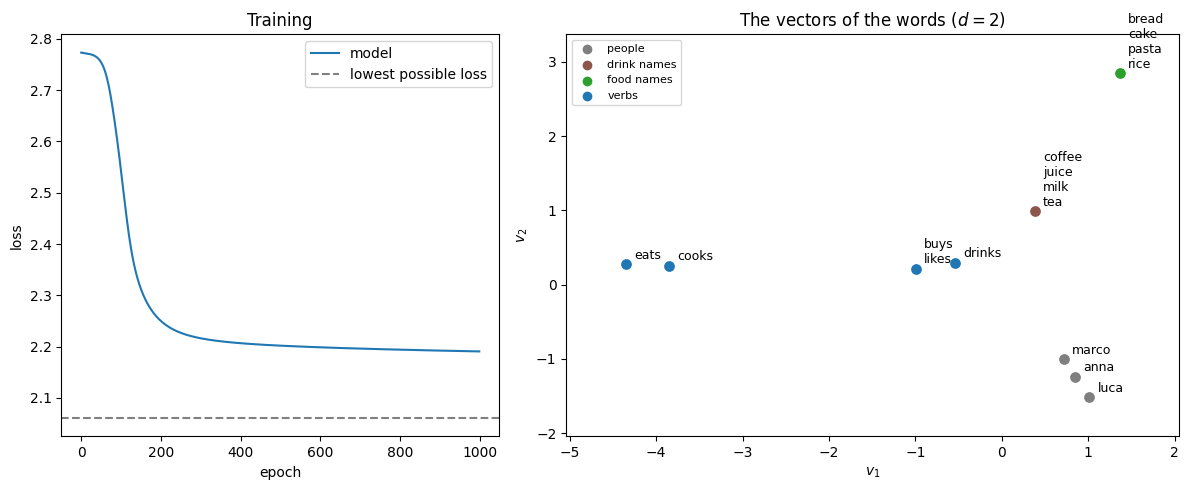

In [5]:
groups = {"people": people, "drink names": drinks, "food names": foods,
          "verbs": ["drinks", "eats", "cooks", "buys", "likes"]}
group_of = {word: group for group, words in groups.items() for word in words}
colors = {"people": "tab:gray", "drink names": "tab:brown", "food names": "tab:green", "verbs": "tab:blue"}

fig, ax = plt.subplots(ncols=2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].plot(history, label="model")
ax[0].axhline(floor, color="gray", linestyle="--", label="lowest possible loss")
ax[0].set_xlabel("epoch")
ax[0].set_ylabel("loss")
ax[0].set_title("Training")
ax[0].legend()

# Words with (almost) the same vector are written together
placed = []
for word in vocabulary:
    point = V_toy[index[word]]
    for entry in placed:
        if np.linalg.norm(entry["point"] - point) < 0.15 and group_of[entry["words"][0]] == group_of[word]:
            entry["words"].append(word)
            break
    else:
        placed.append({"point": point, "words": [word]})
for entry in placed:
    x, y = entry["point"]
    ax[1].scatter(x, y, color=colors[group_of[entry["words"][0]]], s=45)
    ax[1].annotate("\n".join(entry["words"]), (x, y), textcoords="offset points", xytext=(6, 4), fontsize=9)
for group, color in colors.items():
    ax[1].scatter([], [], color=color, label=group)
ax[1].legend(loc="upper left", fontsize=8)
ax[1].set_xlabel("$v_1$")
ax[1].set_ylabel("$v_2$")
ax[1].set_title("The vectors of the words ($d = 2$)")
ax[1].margins(0.12)
plt.tight_layout()

On the left, the **loss** goes from 2.77, the value of a model that gives the same probability to all the 16 words ($\log 16$), to 2.19. The dashed line is the lowest loss that any model could reach by looking only at the center word (2.06): even for the best model the context of a word is not certain, because `anna` can be next to any verb. The best of the five runs (seed 3) is close to it, and the runs do not differ much (from 2.19 to 2.28).

On the right, the **vectors** of the words, with no label anywhere. The words that are used in the same way have the same vector: the four drinks are in a single point, and so are the four foods, and `buys` and `likes` coincide. The three people are close to each other. The verbs `eats` and `cooks`, which are used only with foods, are together on the left, and the verb `drinks` is closer to `buys` and `likes`, that can be followed by a drink, than to `eats` and `cooks`, that cannot. As in the previous notebook the orientation of the plane means nothing: only the distances count.

A thing to notice: `coffee` and `tea` **never occur in the same sentence** (a sentence has a single drink) and nevertheless their vectors are almost the same. What makes two words close is not that they occur together, but that they occur **in the same contexts**, that is, that one can be replaced by the other.

In [6]:
def neighbors(word, vectors, n=3):
    distance = np.linalg.norm(vectors - vectors[index[word]], axis=1)
    order = [i for i in np.argsort(distance) if vocabulary[i] != word][:n]
    return ", ".join(f"{vocabulary[i]} ({distance[i]:.2f})" for i in order)

pd.DataFrame({"closest words (distance)": {w: neighbors(w, V_toy) for w in ["coffee", "bread", "anna", "drinks", "cooks", "buys"]}}
             ).rename_axis("word").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,closest words (distance)
word,
coffee,"juice (0.01), milk (0.01), tea (0.02)"
bread,"pasta (0.05), rice (0.10), cake (0.11)"
anna,"marco (0.27), luca (0.32), drinks (2.07)"
drinks,"likes (0.45), buys (0.46), coffee (1.16)"
cooks,"eats (0.50), buys (2.85), likes (2.86)"
buys,"likes (0.01), drinks (0.46), coffee (1.58)"


In the plane we measure the similarity as a distance. With hundreds of dimensions we will use the cosine, which does not depend on the length of the vectors. The table says the same thing as the plot: the closest words of `coffee` are `juice`, `milk` and `tea` (at 0.01-0.02), those of `bread` are the other foods, those of `anna` the other people. `Buys` and `likes` are at 0.01: for the model they are the same word. The only word that is similar to `cooks` is `eats` (0.50), and then the distance jumps to 2.85.

The toy shows the idea of the paper, and with a corpus of 16 words the softmax is not a problem. With a real vocabulary it is, and we need some more ideas.

## From the toy to the real thing: the ideas of the paper

The model of the toy example works, but it cannot be used as it is on a real corpus. This section explains why, and what the paper (Mikolov et al., 2013) proposes. In the next sections we will build the models that it describes.

### Skip-gram and CBOW

The model of the toy example is the **skip-gram**: from the center word it predicts each of the words of its window. Its mirror image is the **continuous bag of words (CBOW)**: from the words of the window it predicts the center word. Given a text $w_1, \dots, w_T$ and a window $m$:

- the **skip-gram** maximizes $\displaystyle \sum_{t} \sum_{\substack{-m \le j \le m \\ j \ne 0}} \log P(w_{t+j} \mid w_t)$: a prediction for each pair (center, context), that is, up to $2m$ for each position of the text;
- the **CBOW** maximizes $\displaystyle \sum_{t} \log P(w_t \mid w_{t-m}, \dots, w_{t+m})$, where the context enters as the **average of the vectors of its words**, $\bar v = \frac{1}{2m} \sum_{j \ne 0} v_{w_{t+j}}$, and $P(w_t \mid \text{context}) = \mathrm{softmax}(U \bar v)_{w_t}$: a single prediction for each position.

The CBOW is, in fact, **the network of the previous notebook**: the input is a multi-hot vector (the words of the window, as the ingredients of a recipe), the hidden layer combines the vectors of the words that are present, and the output is a softmax. The only change is the target: the center word instead of the cuisine.

The two models learn from the same text in a different way, and the authors of the original implementation report two consequences (it is the description of their code, more than the paper), that we are going to check on our corpus.

- In the CBOW the words of the context are **averaged**, so the information is smoothed, and there is a single update for each position. It is faster to train, and it represents well the frequent words.
- In the skip-gram there is an update for **each pair**: from the same text we get up to $2m$ times more training examples, and a rare word is not diluted in an average. It is more expensive, and it works better with the rare words and with smaller corpora.

### The cost of the softmax

Both models end with a softmax over the vocabulary, and this is a problem. The normalization $\sum_w \exp(u_w \cdot v_c)$ needs the score of **every** word, and the gradient involves **every** row of $U$: as we have seen, $\partial L / \partial u_w = (p_w - y_w)\, v_c$ is not zero for any $w$. For each training pair the cost is proportional to $V \cdot d$, where $V$ is the size of the vocabulary. In the toy example $V = 16$. In our recipes it is some thousands of words, and in a real corpus it is hundreds of thousands, with billions of pairs: this is not feasible.

### Negative sampling

The idea of the **negative sampling** is to stop asking the model *which* of the $V$ words occurs near the center word $c$, and to ask a much simpler question: *is this pair a real one?*

For each real pair $(c, o)$ of the text we build $K$ **negative pairs** $(c, n_1), \dots, (c, n_K)$, where the words $n_k$ are drawn at random from a noise distribution, so that they are very probably *not* the words that occur near $c$. The model becomes a **binary classifier**, as in the first part of the notebook on classification: the probability that a pair is a real one is a sigmoid of the product of the vectors, $\sigma(u_o \cdot v_c)$, with $\sigma(z) = 1 / (1 + e^{-z})$. The loss of a training pair is the cross-entropy, with the real pair as the positive class and the $K$ noise pairs as the negative class:

$$L = -\log \sigma(u_o \cdot v_c) \;-\; \sum_{k=1}^{K} \log \sigma(-u_{n_k} \cdot v_c)$$

The first term pushes up the score of the real pair, the others push down the score of the noise pairs. The gradient involves only $v_c$, $u_o$ and the $K$ vectors $u_{n_k}$: the cost of a pair is proportional to $(K + 2)\, d$ and **does not depend on the size of the vocabulary**. The authors suggest $K$ between 5 and 20 for small corpora, and between 2 and 5 for large ones.

Two remarks. First, the model does not compute $P(o \mid c)$ anymore: it is not a language model, and the loss is only a means to obtain vectors that are able to tell the real pairs from the noise ones. Second, the "negatives" are noise, and not necessarily false: a word that is drawn at random could, by chance, occur near $c$. The method accepts it.

### Two other ingredients

**The noise distribution.** The negative words are drawn with a probability proportional to the frequency of the word raised to the power $3/4$:

$$P_n(w) \propto f(w)^{3/4}$$

With the plain frequency the negatives would be almost always the same few very frequent words. The exponent $3/4$, found empirically by the authors, flattens the distribution: the frequent words are drawn less often, and the rare ones more often.

**Subsampling of the frequent words.** The most frequent words (in a recipe: `the`, `and`, `add`, `minutes`) are in a huge number of pairs, and they say little about the words that are near them. Before building the pairs, each occurrence of a word $w$ is discarded with probability

$$P(\text{discard } w) = 1 - \sqrt{\frac{t}{f(w)}}$$

where $f(w)$ is the frequency of the word and $t$ is a threshold (the paper uses $10^{-5}$ on very large corpora; with a corpus of about a million words a larger value, such as $10^{-3}$, makes more sense). The words that are less frequent than $t$ are never discarded. According to the authors, this speeds up the training and improves the vectors of the rarer words, and it has a side effect: since the frequent words disappear, the window reaches words that were farther away.

### What we are going to build

In the next sections we build, in PyTorch, both the **skip-gram** and the **CBOW**, and we train them on the instructions of the recipes. We do **not** use the negative sampling. Our vocabulary has less than four thousand words, so the softmax is affordable, and above all we want a **predictor**: a model that gives a probability distribution over the words, which the negative sampling does not compute. We keep the other two ideas of the paper, the subsampling of the frequent words and the window of random size. The negative sampling is what makes it possible to train on vocabularies of millions of words, and it is what the `gensim` library uses: we compare with `gensim`, and at the end we use vectors that were trained with it.

*References.* T. Mikolov, K. Chen, G. Corrado, J. Dean, *Efficient Estimation of Word Representations in Vector Space*, 2013. T. Mikolov, I. Sutskever, K. Chen, G. Corrado, J. Dean, *Distributed Representations of Words and Phrases and their Compositionality*, NIPS 2013.

## Word2Vec on the recipes

We now build the real models. The corpus is the **instructions** of the recipes, the same recipes of the previous notebooks: it is real text, with a specific vocabulary and a regular structure. We keep 10% of the recipes aside, and the models never see them: we are going to use them to check what the models have learned.

The text is split into sentences (at the full stops, the colons and the semicolons) and each sentence into lowercase words made of letters, so that the window never crosses the end of a sentence. We do not remove the stop words and we do not lemmatize: the models learn from the text as it is.

In [7]:
import json
import time
import torch

from nlp import word2vec as w2v

with open("/Users/Flint/Data/recipes/foodcom/subsets/recipes_cuisine_tipo_10k.json") as f:
    recipes = json.load(f)

order = np.random.default_rng(0).permutation(len(recipes))
cut = int(0.9 * len(recipes))
train_sentences = [s for i in order[:cut] for s in w2v.sentences_of(recipes[i]["instructions"])]
test_sentences = [s for i in order[cut:] for s in w2v.sentences_of(recipes[i]["instructions"])]

print(f"{cut} recipes for the training, {len(recipes) - cut} kept aside")
print(f"{len(train_sentences)} training sentences, {sum(map(len, train_sentences))} words")
print(recipes[order[0]]["instructions"][:160])
for sentence in train_sentences[:3]:
    print(sentence)

8955 recipes for the training, 996 kept aside
95079 training sentences, 942400 words
Mix the eggs with the sugar until foamy. Add cacao through a sieve and the other spices/flavorings. Let the coconut fat melt on a pan on low heat and add it to 
['mix', 'the', 'eggs', 'with', 'the', 'sugar', 'until', 'foamy']
['add', 'cacao', 'through', 'a', 'sieve', 'and', 'the', 'other', 'spices', 'flavorings']
['let', 'the', 'coconut', 'fat', 'melt', 'on', 'a', 'pan', 'on', 'low', 'heat', 'and', 'add', 'it', 'to', 'the', 'mixture']


We use 8,955 recipes for the training and we keep 996 aside. The training text has 95,079 sentences and 942,400 words. The sentences are short and imperative (*mix the eggs with the sugar until foamy*). The splitting is rough: `spices/flavorings` has become two words, and since we keep only the letters the numbers have disappeared, so that *preheat the oven to 350 degrees* becomes *preheat the oven to degrees*.

In [8]:
vocab = w2v.Vocabulary(train_sentences, min_count=5, subsample=1e-3)
tokens, sentence_ids = vocab.encode(train_sentences)
test_tokens, test_sentence_ids = vocab.encode(test_sentences)

print(f"Vocabulary: {len(vocab)} words; words in the training text that are in the vocabulary: {len(tokens)}")
print(f"Words that can be discarded by the subsampling: {(vocab.keep < 1).sum()}")

ranks = [0, 1, 2, 6, 10, 30, 80, 200, 1000, 3000]
pd.DataFrame({"rank": ranks, "word": [vocab.words[r] for r in ranks], "occurrences": vocab.counts[ranks],
              "probability of keeping it": vocab.keep[ranks]}).style.format({"probability of keeping it": "{:.2f}"}).hide(axis="index")

Vocabulary: 3848 words; words in the training text that are in the vocabulary: 931839
Words that can be discarded by the subsampling: 174


rank,word,occurrences,probability of keeping it
0,the,51334,0.13
1,and,50376,0.14
2,a,26044,0.19
6,add,15281,0.25
10,minutes,12416,0.27
30,medium,4065,0.48
80,cream,1889,0.70
200,onto,803,1.00
1000,yellow,78,1.00
3000,unsweetened,8,1.00


The vocabulary has 3,848 words, the ones that occur at least five times, and they cover 931,839 of the 942,400 words of the training text. The most frequent words are the ones that we expect: `the` has 51,334 occurrences, `and` 50,376, `a` 26,044. The subsampling keeps `the` only 13% of the times, `add` 25%, `medium` 48%, `cream` 70%. Only 174 words are subject to the subsampling: from rank 200 on (`onto`, 803 occurrences) every occurrence is kept.

### The training examples

The examples are built as in the toy example, with two differences that come from the paper. The window is **random**: for each word it is drawn between 1 and 5, so that the closest words are used more often than the farthest ones. And the **frequent words are subsampled** before building the pairs, at every epoch: each occurrence of a word $w$ is kept with probability $\sqrt{t / f(w)}$ (and always, if this is larger than 1), with $t = 10^{-3}$.

As a small example, these are the context words of each word of a sentence, with a window of 2 and without subsampling.

In [9]:
sentence = "preheat the oven to degrees and grease a baking pan".split()
ids, _ = vocab.encode([sentence])
centers, contexts = w2v.skipgram_pairs(ids, np.zeros(len(ids), dtype=int), window=2, rng=np.random.default_rng(0), shrink=False)
pd.DataFrame({"center": [vocab.words[c] for c in ids],
              "context": [", ".join(vocab.words[o] for o in contexts[centers == c]) for c in ids]}).style.hide(axis="index")

center,context
preheat,"the, oven"
the,"oven, preheat, to"
oven,"to, the, degrees, preheat"
to,"degrees, oven, and, the"
degrees,"and, to, grease, oven"
and,"grease, degrees, a, to"
grease,"a, and, baking, degrees"
a,"baking, grease, pan, and"
baking,"pan, a, grease"
pan,"baking, a"


In [10]:
rng = np.random.default_rng(0)
kept_tokens, kept_ids = w2v.subsample(tokens, sentence_ids, vocab, rng)
pairs_centers, _ = w2v.skipgram_pairs(kept_tokens, kept_ids, 5, rng)
cbow_targets = w2v.cbow_examples(kept_tokens, kept_ids, 5, len(vocab), rng)[1]

print(f"Words: {len(tokens)}, after the subsampling: {len(kept_tokens)}")
print(f"Examples of an epoch: {len(pairs_centers)} pairs (center, context) for the skip-gram, {len(cbow_targets)} for the CBOW")

Words: 931839, after the subsampling: 569416
Examples of an epoch: 2218037 pairs (center, context) for the skip-gram, 562797 for the CBOW


In the small example a word is paired with the words that are at most two positions away: `oven` has four contexts (`preheat`, `the`, `to`, `degrees`), the first and the last words have only two. On the whole text the subsampling discards 39% of the words (931,839 become 569,416) and with a window of random size we get 2,218,037 pairs for the skip-gram and 562,797 examples for the CBOW: **the skip-gram has about four times more examples than the CBOW** in an epoch, since it has a pair for each context word, while the CBOW has a single example for each position. With five epochs for the skip-gram and twenty for the CBOW the two models see about eleven million examples each (11.1 and 11.3).

### The two models

The models are in the module `nlp/word2vec.py`. The **skip-gram** is the network of the toy example, with 100 neurons in the hidden layer instead of 2: an embedding layer, that gives the vector of the center word, and a linear layer with a neuron for each word of the vocabulary, followed by the softmax. The **CBOW** is the same network, but the input is the window: the hidden vector is the **average** of the vectors of the words of the window, and the output is the distribution over the center word. In both cases the vectors of the words are the weights of the embedding layer.

The CBOW has one example for each position, the skip-gram up to ten, so for the same number of examples the CBOW needs more epochs. We train the skip-gram for 5 epochs and the CBOW for 20, so that the two models see about the same number of examples.

Training time: skip-gram 27 s, CBOW 33 s
Loss at the last epoch: skip-gram 6.042, CBOW 4.607


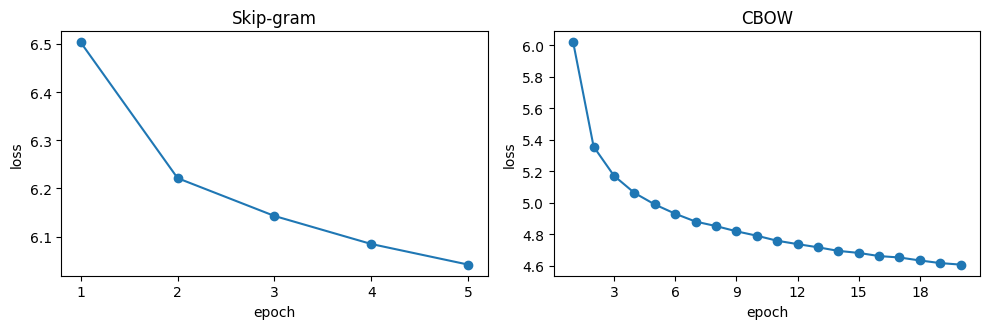

In [11]:
from matplotlib.ticker import MaxNLocator

torch.manual_seed(0)
skipgram = w2v.SkipGram(len(vocab), 100)
cbow = w2v.CBOW(len(vocab), 100)

start = time.time()
history_skipgram = w2v.train(skipgram, vocab, tokens, sentence_ids, epochs=5, verbose=False)
time_skipgram = time.time() - start
start = time.time()
history_cbow = w2v.train(cbow, vocab, tokens, sentence_ids, epochs=20, verbose=False)
time_cbow = time.time() - start

fig, ax = plt.subplots(ncols=2, figsize=(10, 3.4))
for a, history, title in zip(ax, [history_skipgram, history_cbow], ["Skip-gram", "CBOW"]):
    a.plot(range(1, len(history) + 1), history, marker="o")
    a.set_xlabel("epoch")
    a.set_ylabel("loss")
    a.set_title(title)
    a.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
print(f"Training time: skip-gram {time_skipgram:.0f} s, CBOW {time_cbow:.0f} s")
print(f"Loss at the last epoch: skip-gram {history_skipgram[-1]:.3f}, CBOW {history_cbow[-1]:.3f}")

The loss decreases for both, and at the end it is 6.04 for the skip-gram and 4.61 for the CBOW. The two values **cannot be compared**: the skip-gram has to guess one of the ten or so words around a word, and even a perfect model could not do it with certainty (it is the floor of the loss that we saw in the toy example), while the CBOW has to guess one word from the whole window, which is an easier problem. The training takes about half a minute for each model (27 and 33 seconds).

## The model as a predictor

The models that we have trained answer a question. The skip-gram: *which words are likely to occur near this word?* The CBOW: *which word is likely to be in the middle of these words?* Before looking at the vectors, we look at the answers.

### Which words are near a word?

For a center word, the skip-gram gives a probability to each of the 3,848 words of the vocabulary. These are the eight most probable context words for some words, with their probabilities.

In [12]:
def predicted_context(word, n=8):
    probabilities = skipgram.distribution(torch.tensor([vocab.index[word]]))[0]
    return ", ".join(f"{vocab.words[i]} ({probabilities[i]:.2f})" for i in np.argsort(-probabilities)[:n])

pd.DataFrame({"most probable context words": {w: predicted_context(w) for w in ["preheat", "lemon", "whisk", "skillet", "simmer", "chicken"]}}
             ).rename_axis("word").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,most probable context words
word,
preheat,"oven (0.22), degrees (0.15), f (0.13), to (0.08), grill (0.03), c (0.02), broiler (0.02), a (0.01)"
lemon,"juice (0.10), zest (0.03), and (0.02), lemon (0.02), the (0.01), sugar (0.01), peel (0.01), rind (0.01)"
whisk,"together (0.05), bowl (0.03), in (0.03), eggs (0.02), and (0.02), milk (0.02), small (0.02), a (0.02)"
skillet,"large (0.04), heat (0.03), medium (0.03), oil (0.03), in (0.03), over (0.02), high (0.02), a (0.02)"
simmer,"reduce (0.05), minutes (0.04), cover (0.03), heat (0.03), for (0.03), low (0.02), to (0.02), bring (0.02)"
chicken,"the (0.02), and (0.02), broth (0.01), add (0.01), chicken (0.01), pieces (0.01), to (0.01), stock (0.01)"


The answers are sensible. After `preheat` the model expects `oven` (0.22), `degrees` (0.15) and `f` (0.13), the words that follow it in the recipes. For `lemon` the most probable words are `juice` (0.10) and `zest` (0.03), then `peel` and `rind`. For `whisk` we get `together`, `bowl`, `eggs`, for `skillet` `large`, `heat`, `medium`, `oil`, for `simmer` `reduce`, `minutes`, `cover`.

Three things to notice. The probabilities are **small** (at most 0.22): the model has to share the probability among all the words that can be found near a word, and there are many. The frequent words (`and`, `the`) are present, but they are less probable than they would be in the real text, since we trained on text in which they have been subsampled. And a **generic word** gives a flat distribution: for `chicken`, which can be anywhere in a recipe, the most probable words are `the` and `and` with 0.02, and `broth` is at 0.01.

### Which word is in the middle?

The CBOW works the other way round: given the words around a blank, it gives a probability to each word of the vocabulary. We try it on some sentences that we write, and then on sentences of the recipes that the model has never seen.

In [13]:
def fill_blank(text, n=5, window=5):
    words = text.split()
    blank = words.index("___")
    ids = [vocab.index[w] for i, w in enumerate(words) if i != blank and abs(i - blank) <= window and w in vocab.index]
    probabilities = cbow.distribution(np.array([ids + [cbow.padding] * (2 * window - len(ids))]))[0]
    return ", ".join(f"{vocab.words[i]} ({probabilities[i]:.2f})" for i in np.argsort(-probabilities)[:n])

sentences_with_blank = ["preheat the ___ to degrees", "add the chopped ___ and cook until soft", "bake in a preheated ___ for minutes",
                        "whisk the ___ and sugar until smooth", "simmer for minutes until the ___ is tender"]
pd.DataFrame({"most probable words": {s: fill_blank(s) for s in sentences_with_blank}}).rename_axis("sentence").style.set_properties(
    **{"text-align": "left"}).set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])

,most probable words
sentence,
preheat the ___ to degrees,"oven (0.43), f (0.16), degrees (0.04), to (0.03), c (0.03)"
add the chopped ___ and cook until soft,"onion (0.05), onions (0.05), garlic (0.03), potatoes (0.02), vegetables (0.02)"
bake in a preheated ___ for minutes,"oven (0.08), degree (0.07), f (0.06), for (0.04), bake (0.04)"
whisk the ___ and sugar until smooth,"flour (0.03), beat (0.02), milk (0.02), blend (0.02), and (0.02)"
simmer for minutes until the ___ is tender,"about (0.05), or (0.03), minutes (0.02), covered (0.02), reduce (0.02)"


In [14]:
rng = np.random.default_rng(3)
candidates = [s for s in test_sentences if 8 <= len(s) <= 12 and all(w in vocab.index for w in s)]
rows = {}
for k in rng.choice(len(candidates), 8, replace=False):
    sentence = candidates[k]
    position = int(rng.integers(2, len(sentence) - 2))
    blanked = " ".join("___" if i == position else w for i, w in enumerate(sentence))
    rows[blanked] = {"true word": sentence[position], "most probable words": fill_blank(blanked)}
pd.DataFrame(rows).T.rename_axis("sentence of a recipe not seen in the training").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,true word,most probable words
sentence of a recipe not seen in the training,,
add to ___ slowly stirring constantly until smooth and thick,saucepot,"thickened (0.04), stirring (0.03), milk (0.02), cook (0.02), mixture (0.02)"
in a large bowl rinse the ___ and pat thoroughly dry,potatoes,"dry (0.04), chicken (0.03), in (0.02), drain (0.02), and (0.02)"
stir well and saute about minutes ___ the beef mixture,with,"browned (0.03), until (0.03), add (0.02), onion (0.02), stir (0.02)"
bake in ___ oven until cheese is melted minutes,f,"golden (0.05), cheese (0.04), minutes (0.03), f (0.03), melted (0.02)"
use a ___ to scrape these seeds from the bean,knife,"pan (0.03), can (0.02), remove (0.02), spoon (0.02), the (0.02)"
grilling grill the chicken outside ___ grill pan or saute pan,inside,"on (0.04), the (0.03), medium (0.02), until (0.02), for (0.02)"
repeat layers with ___ tortillas meat mixture and cheese,remaining,"remaining (0.08), top (0.03), the (0.03), ending (0.02), of (0.02)"
stir in fish sauce lime ___ and sugar,juice,"juice (0.04), soy (0.03), fish (0.02), and (0.02), vinegar (0.02)"


On the sentences that we wrote the CBOW does well when the context is specific: for *preheat the ___ to degrees* it says `oven` (0.43), and `oven` is also the first answer for *bake in a preheated ___* (0.08). When many words can be there, the probability is shared: *add the chopped ___ and cook until soft* gives `onion` and `onions` (0.05 each) and then `garlic`, `potatoes`, `vegetables`, which are all plausible. It also fails: for *whisk the ___ and sugar until smooth* the word that we had in mind, `eggs`, is not among the first five (`flour`, `beat`, `milk`, `blend`, `and`), and for *simmer for minutes until the ___ is tender* it proposes `about` and `or`.

On eight sentences that the model has never seen, the right word is the first one in two cases (`remaining`, `juice`) and among the first five in three (it is also `f`). The other words are often plausible, such as `spoon` or `can` for *use a ___ to scrape these seeds from the bean* where the right word is `knife`, and sometimes they are not (`golden`, `cheese` for `f`). It is a hard task, because many words can fit: this is why we measure it on many examples.

### How good is it?

For the recipes that we kept aside we build the examples with the same procedure of the training (subsampling and random window) and we measure how much probability the models give to the right word. We use the quantities of the notebook on classification: the **cross-entropy**, its exponential, the **perplexity**, and the **top-$k$ accuracy**, that is, how often the right word is among the $k$ most probable ones. As a reference we use a model that ignores the input and always answers with the frequency of the words.

In [15]:
rng = np.random.default_rng(7)
kept_test, kept_test_ids = w2v.subsample(test_tokens, test_sentence_ids, vocab, rng)

rows = {}
for name, model in [("skip-gram", skipgram), ("CBOW", cbow)]:
    source, target = w2v.examples(model, kept_test, kept_test_ids, 5, np.random.default_rng(1))
    _, train_target = w2v.examples(model, *w2v.subsample(tokens, sentence_ids, vocab, np.random.default_rng(2)), 5, np.random.default_rng(2))
    rows[(name, "model")] = w2v.evaluate(model, source, target)
    rows[(name, "word frequency only")] = w2v.unigram_baseline(train_target, target, len(vocab))

pd.DataFrame(rows).T.drop(columns="cross-entropy").rename_axis(["", ""]).style.format(
    {"perplexity": "{:.0f}", "top-1": "{:.1%}", "top-5": "{:.1%}", "top-10": "{:.1%}"})

Both models are much better than the frequency of the words. The **skip-gram** has a perplexity of 476 against 925 of the reference, and the right context word is among the ten most probable ones in 20.3% of the cases, against 8.8%. The **CBOW** has a perplexity of 180 against 914, and gives the right word as the first one in 13.3% of the cases (the reference: 1.2%), among the first five in 30.5% and among the first ten in 40.0% (8.4%). All of it from text, without a single label.

As before, the numbers have to be read with some care. The perplexities of the skip-gram and of the CBOW are not comparable, for the reason that we have seen, and they refer to text in which the frequent words have been subsampled, so they say nothing about the real text. A perplexity of 476 means that the model is as uncertain as if it had to choose among 476 equally likely words, out of 3,848.

## The embeddings

We now forget the answers of the models and we look at their **vectors**: for each word of the vocabulary, the 100 numbers of its row in the embedding layer. This is the representation of the word that we wanted, and it is a by-product of the task, as in the previous notebook, but this time nobody has told the model what to keep.

### Similar words

As in the toy example, two words are similar if their vectors point in the same direction. We measure it with the **cosine** of the angle between them, that does not depend on the length of the vectors.

In [16]:
vectors = {"skip-gram": w2v.WordVectors(vocab.words, skipgram.vectors()),
           "CBOW": w2v.WordVectors(vocab.words, cbow.vectors())}

def closest(wv, vector, exclude=(), n=5):
    return ", ".join(f"{w} ({s:.2f})" for w, s in wv.nearest(vector, n, exclude=exclude))

words = ["lemon", "bake", "parsley", "skillet", "tablespoon", "chicken", "whisk", "chocolate"]
pd.DataFrame({name: {w: closest(wv, wv[w], exclude=[w], n=6) for w in words} for name, wv in vectors.items()}
             ).rename_axis("word").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,skip-gram,CBOW
word,,
lemon,"lime (0.69), orange (0.66), zest (0.53), juice (0.50), paprika (0.44), honey (0.44)","lime (0.57), orange (0.51), tangerine (0.47), clam (0.39), limes (0.39), lemons (0.38)"
bake,"degrees (0.54), preheated (0.52), puffed (0.52), f (0.50), degree (0.50), inserted (0.47)","broil (0.41), roast (0.39), puffed (0.35), quiche (0.35), flute (0.35), program (0.34)"
parsley,"cilantro (0.57), coriander (0.54), basil (0.52), herbs (0.51), feta (0.51), thyme (0.50)","herbs (0.49), basil (0.47), feta (0.43), coriander (0.41), thyme (0.41), chives (0.41)"
skillet,"saucepan (0.58), frying (0.58), pan (0.57), dutch (0.57), pot (0.55), frypan (0.53)","frypan (0.62), pan (0.56), pot (0.56), saucepan (0.53), stockpot (0.46), dutch (0.45)"
tablespoon,"tablespoons (0.75), teaspoon (0.59), cup (0.58), tbsp (0.54), teaspoons (0.49), tblsps (0.44)","tablespoons (0.76), tbsp (0.65), teaspoons (0.62), teaspoon (0.60), cup (0.51), tsp (0.51)"
chicken,"meat (0.69), beef (0.58), pork (0.57), fish (0.51), lamb (0.51), veal (0.50)","meat (0.68), beef (0.61), pork (0.59), turkey (0.55), lamb (0.54), oxtails (0.53)"
whisk,"beat (0.61), mix (0.59), whisking (0.55), combine (0.52), stir (0.51), yolks (0.50)","mix (0.57), beat (0.54), whisking (0.45), sift (0.43), combine (0.41), mixing (0.40)"
chocolate,"butterscotch (0.50), vanilla (0.47), chips (0.46), mousse (0.45), caramel (0.44), boiler (0.44)","marshmallows (0.40), cocoa (0.39), butterscotch (0.39), caramel (0.39), brandy (0.35), sugared (0.35)"


The neighbors are the ones that we expect from words that are used in the same way. `Lemon` is with `lime` and `orange`, `tablespoon` with `tablespoons`, `teaspoon` and `tbsp`, `skillet` with `saucepan`, `pan` and `frypan`, `chicken` with `meat`, `beef` and `pork`, `parsley` with `cilantro`, `coriander` and `basil`. Nobody told the model that these are fruits, utensils or meats, and it also puts together the different spellings of the same unit (`tbsp`, `tblsps`).

The two models give a different flavor, at least on these words. The skip-gram has among the neighbors words that **occur around** the word (`lemon`: `zest`, `juice`; `bake`: `degrees`, `preheated`, `f`; `whisk`: `yolks`), the CBOW words that **could take its place** (`lemon`: `tangerine`, `limes`, `lemons`; `bake`: `broil`, `roast`; `chocolate`: `cocoa`, `caramel`). It is an observation on eight words, not a rule, and a good question for the discussion is why this could happen. The CBOW has also some strange neighbors (`clam` for `lemon`).

In the previous notebook we looked at some pairs of ingredients with two sets of vectors, the ones of our classifier and the ones of spaCy. This is what the vectors of the contexts say about the same pairs.

In [17]:
pairs = [("cilantro", "coriander"), ("lemon", "lime"), ("tofu", "soy"), ("tofu", "chicken"), ("feta", "cheddar"), ("cumin", "garam"), ("garam", "masala")]
pd.DataFrame({name: {f"{a} - {b}": float(wv_.unit[wv_.index[a]] @ wv_.unit[wv_.index[b]]) for a, b in pairs} for name, wv_ in vectors.items()}
             ).rename_axis("cosine").style.format("{:.2f}")

,skip-gram,CBOW
cosine,,
cilantro - coriander,0.54,0.47
lemon - lime,0.69,0.57
tofu - soy,0.34,0.10
tofu - chicken,0.40,0.44
feta - cheddar,0.30,0.24
cumin - garam,0.48,0.20
garam - masala,0.59,-0.00


In the previous notebook our classifier kept `cilantro` and `coriander` apart (one with the Mexican terms, the other with the Indian ones), while spaCy put them together. The vectors of the contexts agree with spaCy: the cosine is 0.54 for the skip-gram and 0.47 for the CBOW, and `lemon` and `lime` are even closer (0.69 and 0.57). The classifier put `tofu` with `soy`, and spaCy with `chicken` and `pork`: for the contexts `tofu` is a little closer to `chicken` (0.40) than to `soy` (0.34) in the skip-gram, and in the CBOW the cosine with `soy` is only 0.10, against 0.44 with `chicken`. What these vectors tell us is the **kind of thing**, and not the cuisine.

One result that we do not explain: `garam` and `masala`, the two halves of a single ingredient, are similar for the skip-gram (0.59) and not at all for the CBOW (0.00). They are not very frequent words (82 and 137 occurrences, and the thousandth word of the vocabulary has 78), and the authors of Word2Vec say that the skip-gram works better with the less frequent words, but a single pair is not enough to say that this is the reason.

### Operations on the vectors

If the vectors of the words are meaningful, the operations on the vectors should be meaningful as well. We use the skip-gram vectors and we look at four operations: the **sum** of two vectors, the **difference**, the **average** of several vectors, and the search of the word that is **different from the others**. Each time the result is a vector, and what we show are the words that are closest to it.

**Sum.** If `soy` and `sauce` are two words that occur in similar contexts, the sum of their vectors should be close to what has something of both.

In [18]:
wv = vectors["skip-gram"]

sums = [("soy", "sauce"), ("ground", "beef"), ("olive", "oil"), ("lemon", "chicken")]
pd.DataFrame({"closest words": {f"{a} + {b}": closest(wv, wv[a] + wv[b], exclude=[a, b]) for a, b in sums}}
             ).rename_axis("operation").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,closest words
operation,
soy + sauce,"oyster (0.64), teriyaki (0.59), vinegar (0.58), mirin (0.58), sesame (0.56)"
ground + beef,"meat (0.54), turkey (0.54), sausage (0.54), pork (0.53), veal (0.46)"
olive + oil,"butter (0.52), virgin (0.50), vegetable (0.49), canola (0.49), wok (0.49)"
lemon + chicken,"lime (0.63), orange (0.58), and (0.50), the (0.49), fish (0.49)"


The sum works as "a bit of both" when the two words belong together. `Soy + sauce` is close to `oyster`, `teriyaki`, `mirin`, `sesame`: other sauces and ingredients of the same kind. `Ground + beef` is close to other ground meats (`turkey`, `sausage`, `pork`) and `olive + oil` to `virgin` (as in *extra virgin*), `vegetable` and `canola`. It does not work as "the dish that is made of both": `lemon + chicken` is close to `lime` and `orange` and to the very frequent `and` and `the`. The sum of the vectors is not the meaning of a phrase.

**Difference.** The difference of two vectors is the direction that goes from one word to the other.

In [19]:
differences = [("lemon", "juice"), ("hot", "cold"), ("baked", "bake")]
pd.DataFrame({"closest words": {f"{a} - {b}": closest(wv, wv[a] - wv[b], exclude=[a, b]) for a, b in differences}}
             ).rename_axis("operation").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,closest words
operation,
lemon - juice,"omelette (0.32), dillweed (0.30), tzatziki (0.29), template (0.29), cookies (0.29)"
hot - cold,"shimmering (0.29), saute (0.29), sizzles (0.28), smell (0.27), puffs (0.27)"
baked - bake,"leftover (0.36), made (0.35), servings (0.33), great (0.33), doritos (0.32)"


The results are not interpretable, and the cosines are low (0.29-0.36, against about 0.5-0.6 for the sums). What remains when we take `juice` from `lemon` is not a word: `omelette`, `dillweed`, `tzatziki`. The same happens for `hot - cold` (`shimmering`, `sizzles`) and `baked - bake` (`leftover`, `servings`). The difference of two vectors is not a word, and it is not a direction that we can name. It becomes meaningful when it is **added to another word**, as in the analogies.

**Average.** The average of the vectors of several words is a point in the middle of the group: it should be close to what the words of the group have in common.

In [20]:
groups = [["lemon", "lime", "orange"], ["skillet", "saucepan", "wok"], ["whisk", "stir", "beat"], ["onion", "garlic", "carrot"]]
pd.DataFrame({"closest words": {" + ".join(g) + " (average)": closest(wv, np.mean([wv[w] for w in g], axis=0), exclude=g) for g in groups}}
             ).rename_axis("group").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,closest words
group,
lemon + lime + orange (average),"juice (0.55), zest (0.52), honey (0.52), cilantro (0.47), pineapple (0.46)"
skillet + saucepan + wok (average),"pot (0.67), heat (0.58), pan (0.57), dutch (0.55), kettle (0.54)"
whisk + stir + beat (average),"mix (0.69), blend (0.57), mixing (0.56), whisking (0.55), yolks (0.54)"
onion + garlic + carrot (average),"onions (0.68), carrots (0.66), celery (0.62), saute (0.60), bell (0.58)"


The average moves towards what the words have in common, and, as for the sum, towards the words that go with them. `Lemon + lime + orange` is close to `juice` and `zest` (and to `honey`, `cilantro` and `pineapple`): the things that go with the citrus fruit, more than a name for the group. The three pans give `pot`, `pan` and `dutch`, `whisk + stir + beat` gives `mix` and `blend`, `onion + garlic + carrot` gives `onions`, `carrots`, `celery` and `saute`.

**The odd one out.** Given a list of words, the one that is less similar to the average of the others.

In [21]:
lists = [["lemon", "lime", "orange", "chicken"], ["skillet", "saucepan", "wok", "oven"], ["whisk", "stir", "beat", "oven"],
         ["onion", "garlic", "carrot", "sugar"], ["tablespoon", "teaspoon", "cup", "chicken"], ["bake", "roast", "grill", "chop"],
         ["flour", "sugar", "salt", "skillet"], ["minutes", "hours", "seconds", "onion"]]
pd.DataFrame({name: {", ".join(words): wv_.odd_one_out(words)[0] for words in lists} for name, wv_ in vectors.items()}
             ).rename_axis("words").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,skip-gram,CBOW
words,,
"lemon, lime, orange, chicken",chicken,chicken
"skillet, saucepan, wok, oven",oven,oven
"whisk, stir, beat, oven",oven,oven
"onion, garlic, carrot, sugar",sugar,sugar
"tablespoon, teaspoon, cup, chicken",chicken,chicken
"bake, roast, grill, chop",chop,chop
"flour, sugar, salt, skillet",skillet,skillet
"minutes, hours, seconds, onion",onion,onion


Both models find the odd one in all the eight lists: `chicken` among the citrus fruits and among the units of measure, `oven` among the pans and among the verbs for mixing, `sugar` among the vegetables, `chop` among the ways of cooking, `skillet` among the ingredients, `onion` among the units of time. The lists are easy by construction, and it is a good result anyway: nobody has given the model the categories.

### Analogies

The most famous use of the vectors is the **analogy**: *`a` is to `b` as `c` is to what?* If the relation between `a` and `b` is a direction of the space, the answer should be the word that is closest to $v_b - v_a + v_c$, excluding `a`, `b` and `c`. In the example of the paper, $v_{\text{king}} - v_{\text{man}} + v_{\text{woman}}$ is close to $v_{\text{queen}}$. In our corpus we try with some relations that we can find in the recipes.

In [22]:
analogies = [("chop", "chopped", "slice", "sliced"), ("tablespoon", "tablespoons", "teaspoon", "teaspoons"),
             ("minute", "minutes", "hour", "hours"), ("onion", "onions", "carrot", "carrots"),
             ("oven", "bake", "skillet", "fry"), ("whisk", "eggs", "knead", "dough"),
             ("lemon", "lime", "apple", "pear"), ("hot", "cold", "warm", "cool")]
rows = {}
for a, b, c, expected in analogies:
    rows[f"{a} : {b} :: {c} : ?"] = {"expected": expected, **{name: closest(wv_, wv_[b] - wv_[a] + wv_[c], exclude=[a, b, c], n=3)
                                                              for name, wv_ in vectors.items()}}
pd.DataFrame(rows).T.rename_axis("analogy").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,expected,skip-gram,CBOW
analogy,,,
chop : chopped :: slice : ?,sliced,"sliced (0.50), slices (0.42), grated (0.39)","sliced (0.48), focaccia (0.33), snipped (0.31)"
tablespoon : tablespoons :: teaspoon : ?,teaspoons,"teaspoons (0.60), cups (0.47), cup (0.46)","teaspoons (0.62), tsp (0.43), tbsp (0.40)"
minute : minutes :: hour : ?,hours,"hours (0.65), min (0.45), for (0.43)","hours (0.64), mins (0.46), min (0.40)"
onion : onions :: carrot : ?,carrots,"carrots (0.60), sprouts (0.50), green (0.49)","carrots (0.58), sprouts (0.38), chestnuts (0.37)"
oven : bake :: skillet : ?,fry,"saute (0.45), saut (0.44), cook (0.43)","frypan (0.41), dutch (0.40), pan (0.36)"
whisk : eggs :: knead : ?,dough,"springy (0.47), floured (0.46), dough (0.43)","possibly (0.38), deflate (0.35), stem (0.33)"
lemon : lime :: apple : ?,pear,"pineapple (0.48), papaya (0.46), grapefruit (0.44)","pineapple (0.36), fruit (0.36), kielbasa (0.36)"
hot : cold :: warm : ?,cool,"refresh (0.42), water (0.38), yeast (0.36)","warmed (0.37), luke (0.36), scrub (0.34)"


The results are mixed, and this is the interesting thing. The analogies of **form** work: `chop : chopped :: slice : sliced`, `tablespoon : tablespoons :: teaspoon : teaspoons`, `minute : minutes :: hour : hours` and `onion : onions :: carrot : carrots` are answered correctly, as the first word, by both models. The analogies of **meaning** are weaker. For `oven : bake :: skillet : ?` the skip-gram says `saute` and `cook` (verbs for a pan, but not `fry`) and the CBOW gives words for pans; for `whisk : eggs :: knead : ?` the skip-gram has `dough` in the third place, after `springy` and `floured`, and the CBOW does not have it; for `lemon : lime :: apple : ?` they give fruits (`pineapple`, `papaya`, `grapefruit`) but not `pear`; `hot : cold :: warm : ?` fails for both. We chose these examples, and the next table says how often it works.

Some good examples do not tell how often it works. To measure it we build many analogies with the same relation: the nouns of the vocabulary that have a plural with an `s` (`onion : onions`, `sauce : sauces`) and we ask the models to complete `a : b :: c : ?` for 600 random couples of pairs. As a comparison we train the model of the `gensim` library on the same sentences, with the same parameters (skip-gram, window 5, 5 epochs, subsampling $10^{-3}$, 100 dimensions): it is a very optimized implementation, and it uses the negative sampling.

In [23]:
import contextlib
import io
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
from gensim.models import Word2Vec

with contextlib.redirect_stderr(io.StringIO()):      # the C extension of gensim prints some harmless warnings
    gensim_model = Word2Vec(train_sentences, vector_size=100, window=5, min_count=5, sg=1, negative=5, sample=1e-3, epochs=5, workers=1, seed=0)
vectors["gensim (skip-gram)"] = w2v.WordVectors(gensim_model.wv.index_to_key, gensim_model.wv.vectors)

counts = dict(zip(vocab.words, vocab.counts))
plurals = [(w, w + "s") for w in vocab.words if w + "s" in vocab.index and counts[w] >= 30 and counts[w + "s"] >= 30 and len(w) > 3]
print(f"{len(plurals)} pairs singular - plural, for example {plurals[4:8]}")

rows = {}
for name, wv_ in vectors.items():
    top1, top5 = w2v.analogy_accuracy(wv_, plurals)
    rows[name] = {"right answer, first": top1, "right answer, among the first 5": top5}
pd.DataFrame(rows).T.rename_axis("vectors").style.format("{:.1%}")

147 pairs singular - plural, for example [('pepper', 'peppers'), ('sugar', 'sugars'), ('onion', 'onions'), ('cheese', 'cheeses')]


,"right answer, first","right answer, among the first 5"
vectors,,
skip-gram,10.2%,22.3%
CBOW,16.3%,32.5%
gensim (skip-gram),11.7%,28.0%


On 600 analogies of plurals the right answer is the first one in 10.2% of the cases for the skip-gram (22.3% among the first five), in 16.3% (32.5%) for the CBOW and in 11.7% (28.0%) for `gensim`. A random answer in a vocabulary of 3,848 words would be right in 0.03% of the cases, so the vectors know something, but the success is far from what the examples suggested. The CBOW is better than the skip-gram here, and our implementations are in line with `gensim`, even if they are trained in a different way (full softmax for us, negative sampling for `gensim`): we do not expect the same numbers.

The corpus has less than a million words. How the analogies work with a corpus that is one hundred thousand times larger is what we see in the next section.

## Vectors trained by others

Our models have seen less than a million words, and this is the limit that we have met in the analogies. The strength of Word2Vec is that the vectors can be trained **once**, on a very large corpus, and then **reused** by everyone. In 2013 Google published the vectors trained on a collection of news of about **100 billion words**: 3 million words and phrases, with 300 dimensions each, trained with the negative sampling.

The file is large (1.7 GB, and it takes about 3.6 GB of memory to load it all). `gensim` reads it with a single call, and since the words are sorted by frequency we load only the 200,000 most frequent ones, which are enough for us and are loaded in a second.

In [24]:
from gensim.models import KeyedVectors

path = "/Users/Flint/Data/wordvec/word2vec-google-news-300/word2vec-google-news-300.gz"
google = KeyedVectors.load_word2vec_format(path, binary=True, limit=200_000)
google_vectors = w2v.WordVectors(google.index_to_key, google.vectors)

print(f"{len(google)} words, {google.vector_size} dimensions")
print("Most frequent:", google.index_to_key[:12])
print("Phrases:", [w for w in google.index_to_key[:3000] if "_" in w][:6])
print("Case:", [w for w in ["the", "The", "Lemon", "lemon", "Paris", "paris"] if w in google_vectors])

200000 words, 300 dimensions
Most frequent: ['</s>', 'in', 'for', 'that', 'is', 'on', '##', 'The', 'with', 'said', 'was', 'the']
Phrases: ['New_York', 'United_States', 'per_cent', '_', 'Associated_Press', 'Los_Angeles']
Case: ['the', 'The', 'Lemon', 'lemon', 'Paris', 'paris']


We have 200,000 words with 300 dimensions. The vocabulary is built differently from ours. It is made of the raw tokens of the news (`</s>` is the end of a sentence), it keeps the **case** (`The` and `the`, `Lemon` and `lemon`, `Paris` and `paris` are different entries, with different vectors) and it contains **phrases** joined by an underscore (`New_York`, `United_States`, `Associated_Press`), that were found with a statistical method before the training. We have to remember it when we look for a word: `lemon_juice` is an entry of its own.

In [25]:
def closest_to(wv, expression, n=4):
    positive, negative = expression
    vector = sum(wv[w] for w in positive) - sum(wv[w] for w in negative)
    return closest(wv, vector, exclude=positive + negative, n=n)

classic = {"king - man + woman": (["king", "woman"], ["man"]),
           "Paris - France + Italy": (["Paris", "Italy"], ["France"]),
           "Rome - Italy + Japan": (["Rome", "Japan"], ["Italy"])}
pd.DataFrame({"closest words": {name: closest_to(google_vectors, expr) for name, expr in classic.items()}}
             ).rename_axis("operation").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,closest words
operation,
king - man + woman,"queen (0.73), monarch (0.65), princess (0.62), crown_prince (0.58)"
Paris - France + Italy,"Milan (0.73), Rome (0.71), Italian (0.60), Tuscany (0.57)"
Rome - Italy + Japan,"Tokyo (0.68), Seoul (0.55), Fukuoka (0.54), Nagoya (0.53)"


These are the examples of the paper. `King - man + woman` gives `queen` (0.73), followed by `monarch` and `princess`. The geographical relations work as well, but not perfectly: `Paris - France + Italy` gives `Milan` (0.73) and then `Rome` (0.71), while `Rome - Italy + Japan` gives `Tokyo` (0.68). As we did with our vectors, we exclude from the answers the words of the question.

In [26]:
words = ["lemon", "bake", "parsley", "skillet", "tablespoon", "chicken", "whisk", "chocolate"]
pd.DataFrame({"our skip-gram": {w: closest(vectors["skip-gram"], vectors["skip-gram"][w], exclude=[w], n=6) for w in words},
              "Google News": {w: closest(google_vectors, google_vectors[w], exclude=[w], n=6) for w in words}}
             ).rename_axis("word").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,our skip-gram,Google News
word,,
lemon,"lime (0.69), orange (0.66), zest (0.53), juice (0.50), paprika (0.44), honey (0.44)","lemons (0.65), lemon_juice (0.64), apricot (0.62), lime_juice (0.62), cucumber (0.61), lemony (0.61)"
bake,"degrees (0.54), preheated (0.52), puffed (0.52), f (0.50), degree (0.50), inserted (0.47)","Bake (0.69), baking (0.64), cook (0.61), bake_cookies (0.61), bakes (0.58), oven (0.56)"
parsley,"cilantro (0.57), coriander (0.54), basil (0.52), herbs (0.51), feta (0.51), thyme (0.50)","chives (0.79), cilantro (0.78), basil (0.78), fennel (0.78), thyme (0.77), tarragon (0.76)"
skillet,"saucepan (0.58), frying (0.58), pan (0.57), dutch (0.57), pot (0.55), frypan (0.53)","saucepan (0.84), medium_saucepan (0.76), cast_iron_skillet (0.76), roasting_pan (0.75), casserole_dish (0.73), wok (0.73)"
tablespoon,"tablespoons (0.75), teaspoon (0.59), cup (0.58), tbsp (0.54), teaspoons (0.49), tblsps (0.44)","tablespoons (0.86), ¼_cup (0.85), tbsp (0.85), teaspoon (0.83), tsp (0.81), teaspoons (0.77)"
chicken,"meat (0.69), beef (0.58), pork (0.57), fish (0.51), lamb (0.51), veal (0.50)","meat (0.68), Chicken (0.67), chickens (0.66), poultry (0.66), pork (0.65), turkey (0.63)"
whisk,"beat (0.61), mix (0.59), whisking (0.55), combine (0.52), stir (0.51), yolks (0.50)","whisking (0.73), Whisk (0.60), whisked (0.59), whisks (0.58), mixing_bowl (0.53), Stir (0.51)"
chocolate,"butterscotch (0.50), vanilla (0.47), chips (0.46), mousse (0.45), caramel (0.44), boiler (0.44)","dark_chocolate (0.77), chocolates (0.76), Chocolate (0.71), caramel (0.67), ice_cream (0.66), candy (0.64)"


The neighbors are of the same kind as ours, with larger cosines: `saucepan` is at 0.84 from `skillet` in the vectors of Google and at 0.58 in ours, `tablespoons` at 0.86 and 0.75. The vocabulary is raw, and the neighbors include the **capitalized** forms (`Bake`, `Chicken`, `Whisk`), the **forms** of the same word (`lemons`, `whisked`, `whisks`) and the **phrases** (`lemon_juice`, `cast_iron_skillet`, `dark_chocolate`). The relations that are typical of the recipes appear in ours (`bake`: `degrees`, `preheated`; `chocolate`: `chips`, `mousse`) and are not among the first six neighbors in Google's (`bake`: `baking`, `cook`, `oven`; `chocolate`: `dark_chocolate`, `caramel`, `candy`).

The same test of the analogies of plurals, on the same pairs, for all the vectors that we have.

In [27]:
vectors["Google News"] = google_vectors
plurals_google = [(a, b) for a, b in plurals if a in google_vectors and b in google_vectors]
print(f"{len(plurals_google)} pairs")

rows = {}
for name, wv_ in vectors.items():
    top1, top5 = w2v.analogy_accuracy(wv_, plurals_google)
    rows[name] = {"right answer, first": top1, "right answer, among the first 5": top5}
pd.DataFrame(rows).T.rename_axis("vectors").style.format("{:.1%}")

146 pairs


,"right answer, first","right answer, among the first 5"
vectors,,
skip-gram,11.2%,22.5%
CBOW,16.8%,33.0%
gensim (skip-gram),13.7%,30.0%
Google News,62.0%,84.7%


The vectors of Google give the right plural in 62.0% of the cases (84.7% among the first five answers), ours between 11.2% and 16.8% (22.5%-33.0%). The numbers of ours are a little different from the ones of the previous table because here we use the 146 pairs that are also in the vocabulary of Google, and the questions are different. The comparison is, if anything, in favor of ours: Google's vectors choose the answer among 200,000 words, ours among 3,848. The corpus of Google is about one hundred thousand times larger, and the models are of the same family: what makes the difference is the amount of text.

### One word, one vector

The vectors of Google are trained on news, ours on recipes. For many words this is not a difference, but for others it is. These are the closest words of some words of the kitchen in the two sets of vectors.

In [28]:
words = ["stock", "batter", "chops", "starter", "beat", "cream", "jam"]
pd.DataFrame({"our skip-gram (recipes)": {w: closest(vectors["skip-gram"], vectors["skip-gram"][w], exclude=[w], n=5) for w in words},
              "Google News (news)": {w: closest(google_vectors, google_vectors[w], exclude=[w], n=5) for w in words}}
             ).rename_axis("word").style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,our skip-gram (recipes),Google News (news)
word,,
stock,"broth (0.76), bouillon (0.60), liquid (0.55), water (0.51), add (0.47)","shares (0.78), stocks (0.60), Shares (0.58), Stock (0.57), stockmarket (0.55)"
batter,"mixture (0.45), dough (0.43), divided (0.42), spreading (0.41), muffin (0.41)","batters (0.81), leadoff_batter (0.68), inning (0.67), bases_loaded (0.66), baserunner (0.65)"
chops,"cod (0.47), belly (0.43), doves (0.43), breasts (0.41), veal (0.41)","acting_chops (0.54), smarts (0.52), licks (0.50), prowess (0.50), cred (0.47)"
starter,"substituted (0.40), grocery (0.39), pressure (0.38), machine (0.37), seven (0.37)","starters (0.65), redshirt_freshman (0.62), pitcher (0.61), reliever (0.60), redshirt_sophomore (0.60)"
beat,"whisk (0.61), mixer (0.58), speed (0.58), yolks (0.54), beating (0.53)","beating (0.76), beaten (0.67), beats (0.66), trounce (0.65), thumped (0.65)"
cream,"sour (0.56), whip (0.55), milk (0.50), vanilla (0.48), creamy (0.47)","crème (0.71), creams (0.63), Cream (0.62), creme (0.61), lotion (0.56)"
jam,"raspberry (0.44), shot (0.41), top (0.40), strawberry (0.40), preserves (0.39)","jams (0.77), jamming (0.53), bases_loaded_jam (0.50), jammed (0.45), Jams (0.43)"


The words are the same, and the contexts are not. `Stock` is `shares` and `stocks` for the news, `broth` and `bouillon` for the recipes. `Batter` is the baseball player in Google (`leadoff_batter`, `inning`, `baserunner`) and `mixture`, `dough`, `muffin` in ours. `Chops` are `acting_chops` and `smarts` (skills) in the news, and `cod`, `belly`, `breasts`, `veal` (cuts of meat) in the recipes. `Beat` is `trounce` and `thumped` in the news (to defeat), `whisk` and `mixer` in the recipes, `cream` is `crème` and `lotion` for Google, `sour` and `whip` for us. In the opposite direction, `starter` is a player (`pitcher`, `redshirt_freshman`) in Google, and ours has no clear cooking sense (`substituted`, `grocery`).

Two lessons. The vectors **depend on the corpus** on which they have been trained, and they carry its domain: vectors of news are not the best for recipes, and the other way round. And each word has **one vector**, whatever the sense in which it is used: the vector of `stock` is a mix of its senses, in which the most frequent in the corpus prevails (in the news, the financial one).

## Summary

We started from the question that the previous notebook left open: how can we build the representation of a word without labels? The idea is that a word is characterized by its **context**, and we turned it into a task that needs no labels: to predict the words that are around a word (skip-gram), or a word from the words around it (CBOW).

- In the **toy example** the words that can replace each other in the same contexts have the same vector, even when they never occur together (`coffee` and `tea`).
- The cost of the softmax over the whole vocabulary is the reason for the **negative sampling**, that replaces it with a binary classification of real pairs and noise pairs, at the price of not having a probability distribution anymore. For our small vocabulary we kept the softmax, and we obtained two **predictors**: on recipes that they have never seen, the right word is among the first ten in 20.3% of the cases for the skip-gram and in 40.0% for the CBOW, against 8.8% and 8.4% for the frequency of the words.
- The **vectors** give sensible neighbors, groups and odd ones out. The sums and the averages go towards the words that go with the originals, the differences alone mean nothing, and the analogies work well for the forms of the words and poorly for the meanings, if the corpus has less than a million words: with a corpus one hundred thousand times larger they work in more than 60% of the cases.
- The vectors **depend on the corpus** and have one vector for each word.

At the end of the previous notebook we had two representations: one built for a task, which says what an ingredient tells about the cuisine, and one built without labels, which says how a word is used. Now we know how to build the second one, and we have seen its limit: the vector of `stock` is the same in *chicken stock* and in *stock market*. The question that remains open is **what a representation should be like to depend on the sentence in which the word is used**.